<a href="https://colab.research.google.com/github/PR1449/TGbot/blob/main/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import csv

In [5]:
path = '/content/Handling inquiries received from citizens and organizations regarding the city of Pskov (years, administrative-territorial division).csv'
with open (path, encoding='UTF-8') as f:
    x = list(csv.reader(f))

df = pd.DataFrame(x[1:], columns=x[0])

df = df.drop(columns= '')
df['year'] = df['year'].astype(int)
for col in df.columns[1:]:
    df[col] = df[col].astype(int)


In [72]:
path = '/content/Handling inquiries received from citizens and organizations regarding the city of Pskov (months, administrative-territorial division).csv'
with open(path, encoding='UTF-8') as f:
    xx = list(csv.reader(f))
df2 = pd.DataFrame(xx[1:], columns=xx[0])

for col in df2.columns[1:]:
    df2[col] = df2[col].astype(int)

# График 1.


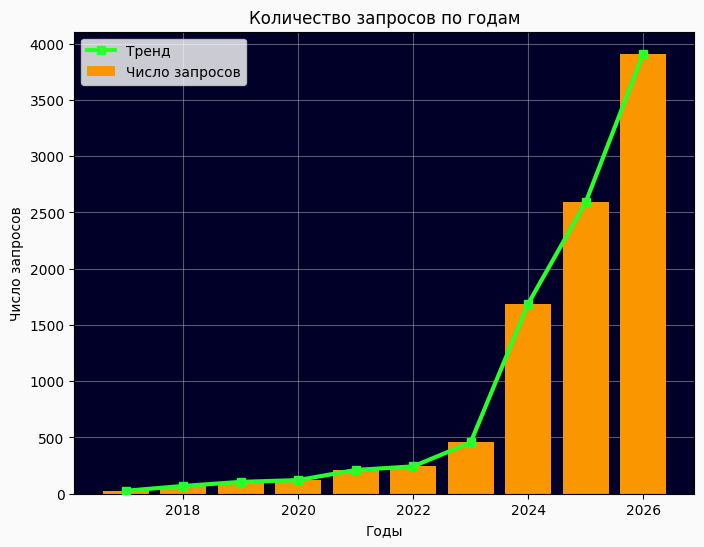

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
fig.patch.set_facecolor('#fafafa')
ax.set_facecolor('#000029')

col = df.columns[1]
ax.bar(df['year'], df[col], color='#fa9600', label='Число запросов', zorder=2)
plt.plot(df['year'], df[col], marker='s', color='#29ff29', linewidth=3, label='Тренд', zorder=3)


plt.title('Количество запросов по годам')
plt.xlabel('Годы')
plt.ylabel('Число запросов')
plt.legend()

plt.grid(zorder=1, alpha=0.5)
plt.show()

# График 2.

In [17]:
cnt_users_answer = system_col = df.columns[6]
assess_cols = list(df.columns[7:11])

pct = df[assess_cols].div(df[cnt_users_answer], axis=0) * 100

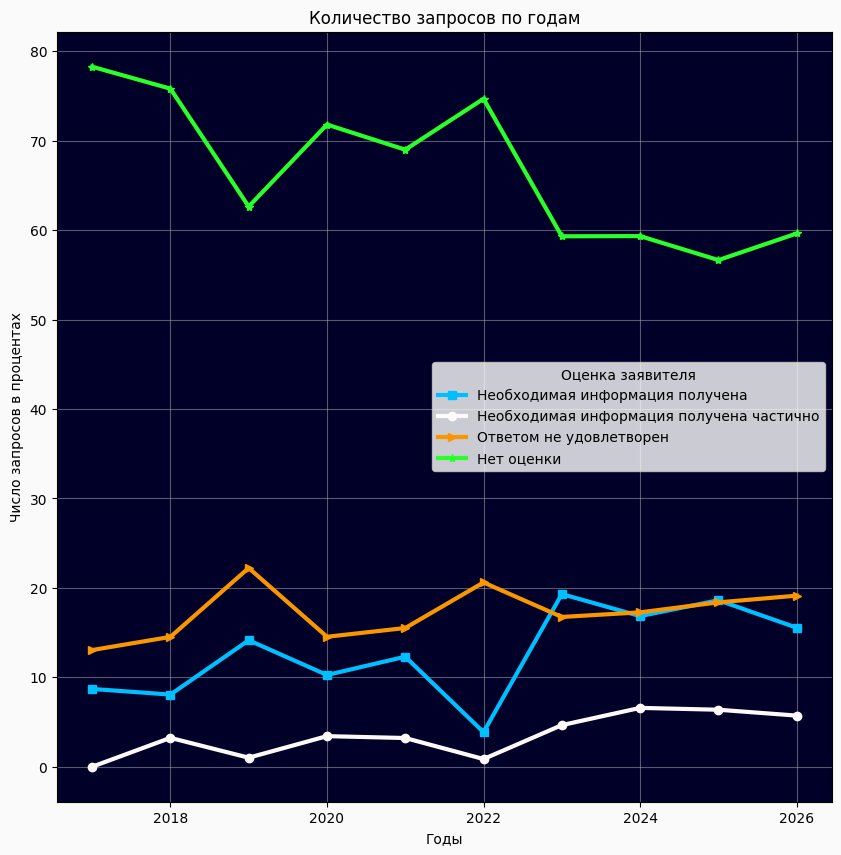

In [37]:
fig, ax = plt.subplots(figsize=(10, 10))
fig.patch.set_facecolor('#fafafa')
ax.set_facecolor('#000029')

col = df.columns[1]
plt.plot(df['year'], pct[assess_cols[0]], marker='s', color='#00bfff', linewidth=3, label='Необходимая информация получена', zorder=2)
plt.plot(df['year'], pct[assess_cols[1]], marker='o', color='#fffafa', linewidth=3, label='Необходимая информация получена частично', zorder=2)
plt.plot(df['year'], pct[assess_cols[2]], marker='>', color='#fa9600', linewidth=3, label='Ответом не удовлетворен', zorder=2)
plt.plot(df['year'], pct[assess_cols[3]], marker='*', color='#29ff29', linewidth=3, label='Нет оценки', zorder=2)


plt.title('Количество запросов по годам')
plt.xlabel('Годы')
plt.ylabel('Число запросов в процентах')
plt.legend(title='Оценка заявителя')

plt.grid(zorder=1, alpha=0.5)
plt.show()

# График 3

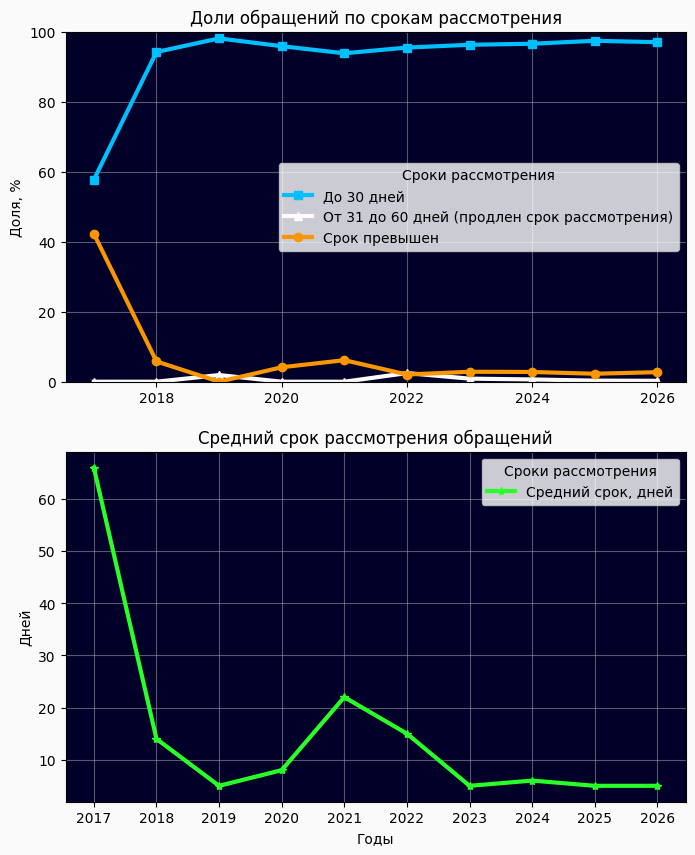

In [68]:
total_col = df.columns[1]
avg_days_col = df.columns[2]
period_cols = list(df.columns[3:6])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 10))
fig.patch.set_facecolor('#fafafa')
ax1.set_facecolor('#000029')
ax2.set_facecolor('#000029')

ax1.plot(df['year'], df[period_cols[0]] / df[total_col] * 100, marker='s', color='#00bfff', linewidth=3, label='До 30 дней', zorder=2)
ax1.plot(df['year'], df[period_cols[1]] / df[total_col] * 100, marker='^', color='#fffafa', linewidth=3, label='От 31 до 60 дней (продлен срок рассмотрения)', zorder=2)
ax1.plot(df['year'], df[period_cols[2]] / df[total_col] * 100, marker='o', color='#fa9600', linewidth=3, label='Срок превышен', zorder=2)
ax2.plot(df['year'], df[avg_days_col], marker='*', color='#29ff29', linewidth=3, label='Средний срок, дней', zorder=2)

ax1.set_title('Доли обращений по срокам рассмотрения')
ax1.set_ylabel('Доля, %')
ax1.set_ylim(0, 100)
ax1.legend(title='Сроки рассмотрения')
ax1.grid(zorder=1, alpha=0.5)

ax2.set_title('Средний срок рассмотрения обращений')
ax2.set_xlabel('Годы')
ax2.set_ylabel('Дней')
ax2.set_xticks(df['year'])
ax2.legend(title='Сроки рассмотрения')
ax2.grid(zorder=1, alpha=0.5)

plt.show()

# График 4

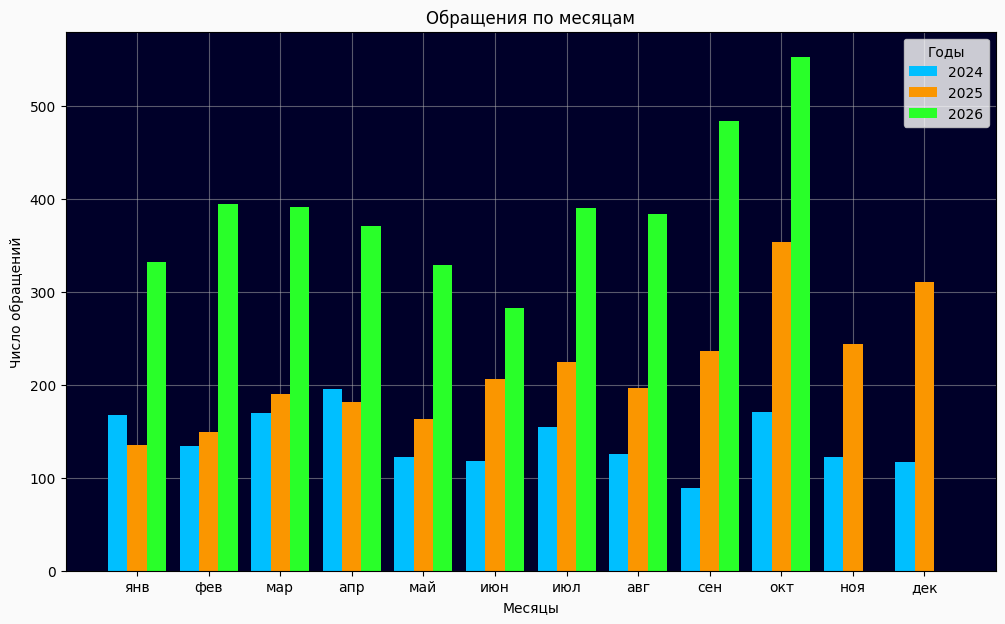

In [74]:
fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor('#fafafa')
ax.set_facecolor('#000029')

x = np.arange(len(df2['month']))
width = 0.27
ax.bar(x - width, df2['2024'], width, color='#00bfff', label='2024', zorder=2)
ax.bar(x, df2['2025'], width, color='#fa9600', label='2025', zorder=2)
ax.bar(x + width, df2['2026'], width, color='#29ff29', label='2026', zorder=2)

ax.set_title('Обращения по месяцам')
ax.set_xlabel('Месяцы')
ax.set_ylabel('Число обращений')
ax.set_xticks(x)
ax.set_xticklabels(['янв', 'фев', 'мар', 'апр', 'май', 'июн', 'июл', 'авг', 'сен', 'окт', 'ноя', 'дек'])
ax.legend(title='Годы')

ax.grid(zorder=1, alpha=0.5)
plt.show()